# Overall の IP プロトコル分布

対象は MAWI Traffic Archive Samplepoint-F の 2026年4月8日 14:00–14:15 JST（開始を含み終了を含まない）です。Task 1 が出力した CSV と JSON から、パケット数と通信量の構成および1分ごとの変化を確認します。設定セルを編集し、上から順に実行してください。

In [1]:
from pathlib import Path

# None ならリポジトリのルート、または notebook/ から既定の結果を探します。
RESULTS_DIR = None  # 例 Path("/path/to/results/202604081400")
# 集計元が人工データの場合は出典を明示します。例 "Synthetic fixture (not MAWI measurements)"
DATA_LABEL = None
IP_VERSION = "both"  # "ipv4", "ipv6", "both"
BYTE_METRIC = "original_frame_bytes"  # または "ip_packet_bytes"
TIMESERIES_RATIO_METRIC = "packet_count"  # または "bytes"（BYTE_METRIC を使用）
SORT_BY = "packet_count"  # 構成比の並べ替え。"bytes" も指定可

# 図1〜3で、出現した番号を個別表示します。閾値以上のプロトコルも個別表示します。
DISPLAY_PROTOCOLS = (6, 17, 1, 58, 47, 50)
OTHERS_THRESHOLD_PCT = 1.0  # パケット比・バイト比のどちらも閾値未満なら Others。None は指定番号のみ
FIGSIZE = (11, 4.6)  # 基本サイズ（インチ）。項目が多い場合は読みやすさのため拡張
SAVE_FIGURES = False  # True の場合のみ RESULTS_DIR / "figures" に PNG を書き出す

## データの読み込みと観測全体の概要

概要表は Task 1 の集計対象全体です。分類不能件数には、IPバージョンが分かるものと分からないものが含まれます。前者は IPv4・IPv6 の件数にも含まれます。プロトコル別の表には CSV の元の列を表示します。

In [2]:
import json
from datetime import timedelta, timezone

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

%matplotlib inline

VERSION_NUMBERS = {"ipv4": (4,), "ipv6": (6,), "both": (4, 6)}
VERSION_LABELS = {"ipv4": "IPv4", "ipv6": "IPv6", "both": "IPv4 + IPv6"}
BYTE_LABELS = {
    "original_frame_bytes": "Original frame bytes (PCAP orig_len)",
    "ip_packet_bytes": "IP packet bytes (known lengths)",
}
if IP_VERSION not in VERSION_NUMBERS or BYTE_METRIC not in BYTE_LABELS:
    raise ValueError("IP_VERSION または BYTE_METRIC の設定を確認してください。")
if {SORT_BY, TIMESERIES_RATIO_METRIC} - {"packet_count", "bytes"}:
    raise ValueError('SORT_BY と TIMESERIES_RATIO_METRIC は "packet_count" または "bytes" を指定してください。')
if OTHERS_THRESHOLD_PCT is not None and not 0 <= OTHERS_THRESHOLD_PCT <= 100:
    raise ValueError("OTHERS_THRESHOLD_PCT は 0〜100 または None を指定してください。")

root = Path.cwd()
if root.name == "notebook":
    root = root.parent
results_dir = Path(RESULTS_DIR if RESULTS_DIR is not None else root / "results" / "202604081400")
results_dir = results_dir.expanduser().resolve()
input_files = ("protocol_counts.csv", "protocol_timeseries_60s.csv", "summary.json", "manifest.json")
missing = [name for name in input_files if not (results_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"集計済みファイルが不足しています ({results_dir})。不足: {', '.join(missing)}。"
        "リポジトリのルートで python3 -m mawi_protocol_analysis /path/to/202604081400.pcap.gz "
        "を実行して4ファイルを生成し、RESULTS_DIR を確認してください。"
    )

COUNTERS = ["packet_count", "original_frame_bytes", "ip_packet_bytes",
            "ip_length_known_packets", "ip_length_unavailable_packets", "fragment_packets"]
CSV_DTYPES = {"category": "string", "ip_version": "Int64",
              "protocol_number": "Int64", "protocol_name": "string"}

def read_csv(name):
    types = CSV_DTYPES | dict.fromkeys(COUNTERS, "int64")
    frame = pd.read_csv(results_dir / name, dtype=types)
    required = set(CSV_DTYPES) | set(COUNTERS)
    if name == "protocol_timeseries_60s.csv":
        required |= {"interval_start_jst", "interval_end_jst"}
    if missing_columns := required - set(frame.columns):
        raise ValueError(f"{name} に Task 1 の列がありません: {', '.join(sorted(missing_columns))}")
    return frame

counts = read_csv("protocol_counts.csv")
timeseries = read_csv("protocol_timeseries_60s.csv")
summary = json.loads((results_dir / "summary.json").read_text(encoding="utf-8"))
manifest = json.loads((results_dir / "manifest.json").read_text(encoding="utf-8"))

window = summary["analysis_window"]
if window != manifest["analysis_window"]:
    raise ValueError("summary.json と manifest.json の対象期間が異なります。")
dataset = manifest["dataset"]
dataset_caption = DATA_LABEL or f"{dataset['name']} / {dataset['samplepoint']}"
jst = timezone(timedelta(hours=9), name="JST")
start_time = pd.Timestamp(window["start_jst"]).tz_convert(jst)
end_time = pd.Timestamp(window["end_jst"]).tz_convert(jst)
window_caption = f"{start_time:%Y-%m-%d %H:%M}–{end_time:%H:%M} JST"
population_label = VERSION_LABELS[IP_VERSION]
byte_label = BYTE_LABELS[BYTE_METRIC]
scope_caption = f"{dataset_caption} · {window_caption} · {population_label}"

# 同じ対象期間でも、別の解析から生成したCSV同士は混ぜられません。
groups = list(CSV_DTYPES)
csv_totals = counts.groupby(groups, dropna=False)[COUNTERS].sum()
minute_totals = timeseries.groupby(groups, dropna=False)[COUNTERS].sum()
if not csv_totals.equals(minute_totals):
    raise ValueError("CSV group totals differ: 全期間CSVと時系列CSVが同じ解析の出力か確認してください。")

overall = summary["populations"]["overall"]
if any(counts[column].sum() != overall[column] for column in COUNTERS):
    raise ValueError("全期間CSVと summary.json の合計が異なります。同じ解析の出力を使用してください。")
overview = {
    "Dataset": dataset_caption,
    "Observation window (JST)": f"[{start_time.isoformat()}, {end_time.isoformat()})",
    "Records read": summary["records_read"],
    "Packets included (Overall)": summary["included_packets"],
    "IPv4 packets": summary["ipv4_packets"],
    "IPv6 packets": summary["ipv6_packets"],
    "Non-IP packets": summary["non_ip_packets"],
    "Unclassifiable packets": summary["unclassifiable_packets"],
    "  Unknown IP version": summary["unknown_version_packets"],
    "  Known IP version, indeterminate protocol": summary["ip_protocol_indeterminate_packets"],
    "TCP packets": summary["tcp_packets"],
    "UDP packets": summary["udp_packets"],
    "Non-TCP/UDP packets (known IP protocol)": summary["non_tcp_udp_packets"],
    "Original frame bytes": overall["original_frame_bytes"],
    "IP packet bytes (known lengths)": overall["ip_packet_bytes"],
    "Packets with unavailable IP length": summary["ip_length_unavailable_packets"],
}
display(pd.Series(overview, name="Overall").to_frame())
display(counts)

,Overall
Dataset,MAWI Traffic Archive / Samplepoint-F
Observation window (JST),"[2026-04-08T14:00:00+09:00, 2026-04-08T14:15:0..."
Records read,294990801
Packets included (Overall),294929893
IPv4 packets,246310569
IPv6 packets,48242335
Non-IP packets,376989
Unclassifiable packets,64
Unknown IP version,0
"Known IP version, indeterminate protocol",64


,category,ip_version,protocol_number,protocol_name,packet_count,original_frame_bytes,ip_packet_bytes,ip_length_known_packets,ip_length_unavailable_packets,fragment_packets,...,original_frame_byte_ratio_overall,ip_packet_byte_ratio_overall,packet_ratio_ip_version,original_frame_byte_ratio_ip_version,ip_packet_byte_ratio_ip_version,mean_original_frame_size,mean_ip_packet_size,packets_per_second,original_frame_bytes_per_second,ip_packet_bytes_per_second
0,ipv4,4,1,ICMP,41653936,2831078288,1793120586,41653936,0,986,...,9.632372e-03,6.198203e-03,1.691114e-01,1.190116e-02,7.664054e-03,67.966645,43.048047,46282.151111,3.145643e+06,1.992356e+06
1,ipv4,4,6,TCP,116312634,166727306307,165098871018,116312634,0,957,...,5.672678e-01,5.706902e-01,4.722194e-01,7.008806e-01,7.056562e-01,1433.441068,1419.440566,129236.260000,1.852526e+08,1.834432e+08
2,ipv4,4,9,IGP,7,420,280,7,0,0,...,1.428995e-09,9.678640e-10,2.841941e-08,1.765577e-09,1.196760e-09,60.000000,40.000000,0.007778,4.666667e-01,3.111111e-01
3,ipv4,4,17,UDP,74003605,58651048939,57600663590,74003605,0,834626,...,1.995525e-01,1.991057e-01,3.004484e-01,2.465546e-01,2.461935e-01,792.543133,778.349428,82226.227778,6.516783e+07,6.400074e+07
4,ipv4,4,41,IPv6-in-IPv4,382,35172,29824,382,0,0,...,1.196681e-07,1.030913e-07,1.550888e-06,1.478544e-07,1.274720e-07,92.073298,78.073298,0.424444,3.908000e+01,3.313778e+01
5,ipv4,4,47,GRE,1434267,935823833,915744095,1434267,0,0,...,3.184018e-03,3.165413e-03,5.823002e-03,3.933973e-03,3.914021e-03,652.475329,638.475329,1593.630000,1.039804e+06,1.017493e+06
6,ipv4,4,50,ESP,12904414,8737145176,8556462340,12904414,0,90963,...,2.972699e-02,2.957676e-02,5.239083e-02,3.672881e-02,3.657154e-02,677.066403,663.064773,14338.237778,9.707939e+06,9.507180e+06
7,ipv4,4,97,ETHERIP,1294,157868,139752,1294,0,0,...,5.371251e-07,4.830747e-07,5.253530e-06,6.636383e-07,5.973200e-07,122.000000,108.000000,1.437778,1.754089e+02,1.552800e+02
8,ipv4,4,103,PIM,30,2160,1740,30,0,0,...,7.349116e-09,6.014583e-09,1.217975e-07,9.080109e-09,7.437009e-09,72.000000,58.000000,0.033333,2.400000e+00,1.933333e+00
9,ipv6,6,<NA>,Indeterminate,64,48436,47540,64,0,0,...,1.647971e-07,1.643295e-07,1.326636e-06,8.648172e-07,8.591802e-07,756.812500,742.812500,0.071111,5.381778e+01,5.282222e+01


## 図1　プロトコル別の構成比

分母は選択した IPv4・IPv6 の合計です。IPバージョンが分かるプロトコル判定不能行は Indeterminate として含め、非IP・IPバージョン不明行は除外します。両バージョンを選ぶと、同じプロトコル番号のカウンタを合算します。同じ番号に複数の名称がある場合は表示ラベルに併記します。

元フレーム長は PCAP の orig_len です。IP長は IPv4 の Total Length、または IPv6 の40バイトと Payload Length の和です。IPバイト数の分母には、IP長を取得できたパケットのバイト数を合計します。元フレーム長と IP長は、元のカウンタからそれぞれ構成比を計算します。

図1〜3では全期間のパケット比と選択したバイト比を使って共通の表示分類を決めます。指定した番号と判定不能行は個別に表示します。残りは閾値以上のものを個別に残し、残余を Others として表示します。下の表で、選択した母集団のIP長の取得件数と取得不能件数を確認できます。

,IPv4 + IPv6
packet_count,294552904
ip_length_known_packets,294552904
ip_length_unavailable_packets,0


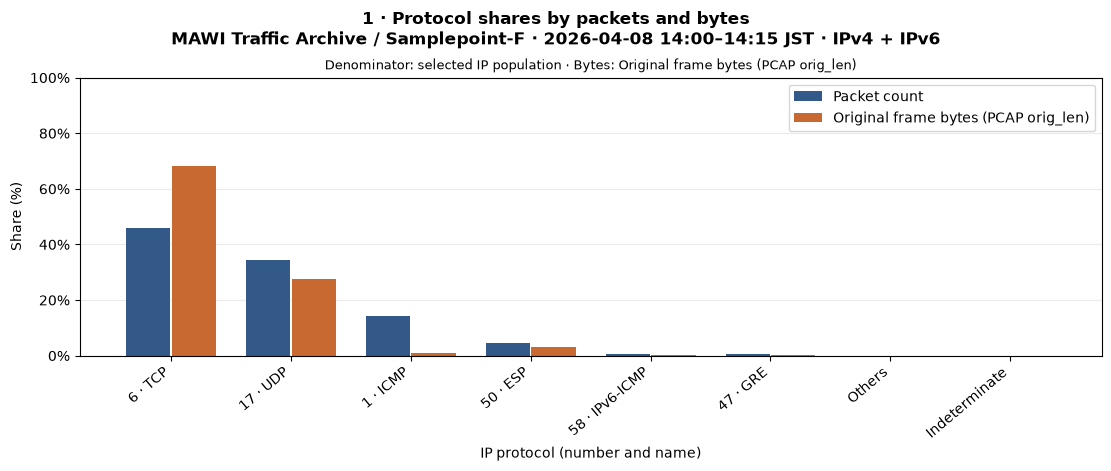

In [3]:
MEASURES = ["packet_count", "original_frame_bytes", "ip_packet_bytes"]
SORT_FIELD = BYTE_METRIC if SORT_BY == "bytes" else SORT_BY
RATIO_FIELD = BYTE_METRIC if TIMESERIES_RATIO_METRIC == "bytes" else TIMESERIES_RATIO_METRIC

def select_ip(frame):
    selected = frame.loc[frame["ip_version"].isin(VERSION_NUMBERS[IP_VERSION])]
    return selected.assign(protocol=selected["protocol_number"].astype("string").fillna("Indeterminate"))

selected_counts = select_ip(counts)
selected_timeseries = select_ip(timeseries)
protocol_totals = selected_counts.groupby("protocol", sort=False)[MEASURES].sum()
labels = {"Indeterminate": "Indeterminate", "Others": "Others"}
for protocol, group in selected_counts.groupby("protocol", sort=False):
    if protocol != "Indeterminate":
        names = " / ".join(sorted(group["protocol_name"].unique()))
        labels[protocol] = f"{protocol} · {names}"

coverage = selected_counts[["packet_count", "ip_length_known_packets", "ip_length_unavailable_packets"]].sum()
display(coverage.rename(population_label).to_frame())

def percentages(values, axis):
    totals = values.sum(axis=axis)
    # Zero denominators are undefined. Keep NaN so that plots can mark those intervals.
    return values.div(totals.where(totals.ne(0)), axis=1 - axis).astype(float) * 100

all_ratios = percentages(protocol_totals, axis=0)
keep = protocol_totals.index.isin([str(number) for number in DISPLAY_PROTOCOLS] + ["Indeterminate"])
if OTHERS_THRESHOLD_PCT is not None:
    keep |= all_ratios[["packet_count", BYTE_METRIC]].ge(OTHERS_THRESHOLD_PCT).any(axis=1).to_numpy()
display_group = {
    protocol: protocol if separate else "Others"
    for protocol, separate in zip(protocol_totals.index, keep)
}
shown_totals = protocol_totals.groupby(display_group, sort=False).sum()
shown_totals = shown_totals.sort_values(SORT_FIELD, ascending=False, kind="stable")
protocol_ratios = percentages(shown_totals, axis=0)

def finish(fig, filename):
    if SAVE_FIGURES:
        figure_dir = results_dir / "figures"
        figure_dir.mkdir(exist_ok=True)
        fig.savefig(figure_dir / f"{filename}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def plot_comparison(ratios, title, denominator, filename):
    width, height = FIGSIZE
    fig, ax = plt.subplots(figsize=(max(width, len(ratios) * 0.46), height), layout="constrained")
    fig.suptitle(f"{title}\n{scope_caption}", fontweight="bold")
    ax.set_title(denominator, fontsize=9)
    xs = list(range(len(ratios)))
    for metric, label, color, offset in (
        ("packet_count", "Packet count", "#325987", -0.19),
        (BYTE_METRIC, byte_label, "#C86931", 0.19),
    ):
        values = ratios[metric]
        if values.notna().any():
            ax.bar([x + offset for x in xs], values, width=0.37, color=color, label=label)
    ax.set_xticks(xs, [labels[protocol] for protocol in ratios.index], rotation=40, ha="right")
    ax.set(xlabel="IP protocol (number and name)", ylabel="Share (%)", ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    handles, _ = ax.get_legend_handles_labels()
    if handles:
        ax.legend(loc="upper right")
    if not ratios["packet_count"].notna().any():
        ax.text(0.5, 0.5, "No packets in this population", ha="center", transform=ax.transAxes)
    elif not ratios[BYTE_METRIC].notna().any():
        ax.text(0.02, 0.95, "No byte total for the selected metric", va="top", transform=ax.transAxes)
    finish(fig, filename)

plot_comparison(protocol_ratios, "1 · Protocol shares by packets and bytes",
                f"Denominator: selected IP population · Bytes: {byte_label}", "01_protocol_shares")

## 図2　1分ごとのプロトコル構成比

各棒の分母は、その1分間の選択母集団のパケット数、または選択したバイト数です。分母が0の区間は、灰色の背景で比率が未定義であることを示します。開始時刻を JST で表示します。

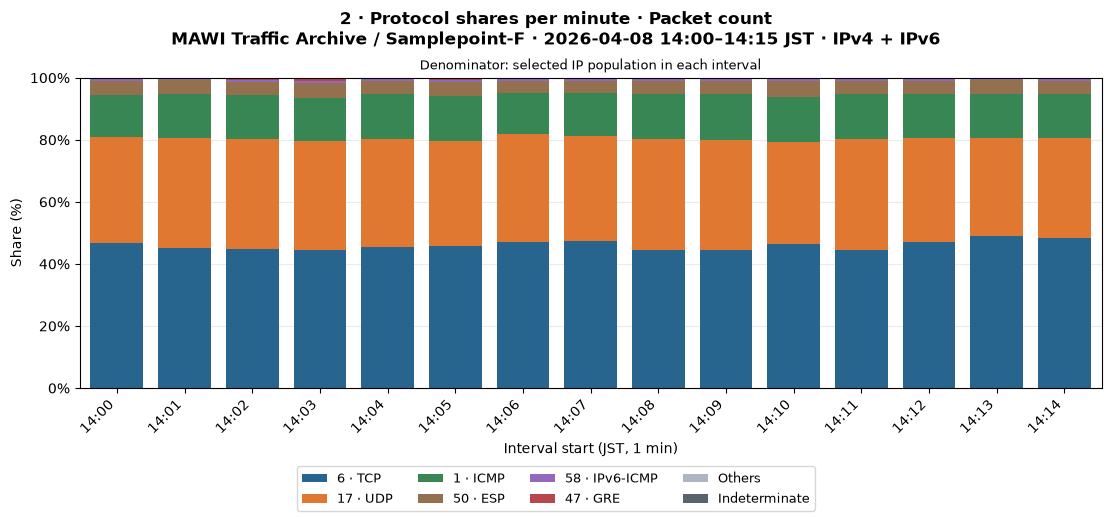

In [4]:
starts = "interval_start_jst"
ends = "interval_end_jst"
interval_table = pd.DataFrame(summary["intervals"])
interval_starts = pd.DatetimeIndex(pd.to_datetime(interval_table[starts], utc=True)).tz_convert(jst)
interval_ends = pd.DatetimeIndex(pd.to_datetime(interval_table[ends], utc=True)).tz_convert(jst)
interval_seconds = (interval_ends - interval_starts).total_seconds().astype(int)
expected_pairs = set(zip(interval_table[starts], interval_table[ends]))
csv_pairs = set(zip(timeseries[starts], timeseries[ends]))
if (len(interval_starts) != 15 or interval_starts[0] != start_time or interval_ends[-1] != end_time
        or not (interval_seconds == 60).all() or not interval_starts[1:].equals(interval_ends[:-1])
        or (not timeseries.empty and csv_pairs != expected_pairs)):
    raise ValueError("時系列CSVと集計概要が、対象期間の連続した15個の1分区間と一致しません。")

timeline = selected_timeseries.assign(
    minute=pd.to_datetime(selected_timeseries[starts], utc=True).dt.tz_convert(jst),
    display_group=selected_timeseries["protocol"].map(display_group),
)
x = list(range(len(interval_starts)))
minute_labels = interval_starts.strftime("%H:%M")
plot_order = shown_totals.index

def time_values(metric):
    counts_by_minute = timeline.groupby(["minute", "display_group"])[metric].sum().unstack(fill_value=0)
    # The summary defines the 15 bins even for an empty selected population.
    return counts_by_minute.reindex(index=interval_starts, columns=plot_order, fill_value=0)

fixed_colors = {"6": "#28658E", "17": "#E17832", "1": "#398655", "58": "#9469BD",
                "47": "#B7464E", "50": "#93714F", "Indeterminate": "#59636B", "Others": "#ADB5C2"}
palette = plt.get_cmap("tab20")
colors = {key: fixed_colors.get(key, palette(int(key) % 20) if key.isdecimal() else "#59636B")
          for key in plot_order}

def time_axis(ax):
    ax.set_xticks(x, minute_labels, rotation=45, ha="right")
    ax.set(xlabel="Interval start (JST, 1 min)", xlim=(-0.55, len(x) - 0.45))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

def time_figure(rows, legend_items):
    width, height = FIGSIZE
    extra_height = 0.24 * ((legend_items + 3) // 4)
    return plt.subplots(rows, 1, sharex=True, figsize=(max(width, 9), height * rows + extra_height),
                        layout="constrained")

minute_values = time_values(RATIO_FIELD)
time_ratios = percentages(minute_values, axis=1)
no_denominator = minute_values.sum(axis=1).eq(0)
fig, ax = time_figure(1, len(plot_order) + int(no_denominator.any()))
ratio_label = "Packet count" if RATIO_FIELD == "packet_count" else byte_label
fig.suptitle(f"2 · Protocol shares per minute · {ratio_label}\n{scope_caption}", fontweight="bold")
ax.set_title("Denominator: selected IP population in each interval", fontsize=9)
bottom = [0.0] * len(x)
for key, values in time_ratios.fillna(0).items():
    ax.bar(x, values, bottom=bottom, width=0.78, color=colors[key], label=labels[key])
    bottom = [previous + value for previous, value in zip(bottom, values)]
for position in no_denominator[no_denominator].index:
    index = interval_starts.get_loc(position)
    ax.axvspan(index - 0.39, index + 0.39, facecolor="#E7EAEE", zorder=0)
handles, legend_labels = ax.get_legend_handles_labels()
if no_denominator.any():
    handles.append(Patch(facecolor="#E7EAEE"))
    legend_labels.append("Undefined (zero denominator)")
if handles:
    fig.legend(handles, legend_labels, loc="outside lower center", ncols=min(4, len(handles)), fontsize=9)
ax.set(ylabel="Share (%)", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
time_axis(ax)
finish(fig, "02_minute_shares")

## 図3　プロトコル別の通信量

各区間のパケット数と選択したバイト数を60秒で割った平均値です。区間内の対象通信量が0の場合、毎秒値は0です。IPバイト毎秒値は取得できたIP長に基づく通信量です。

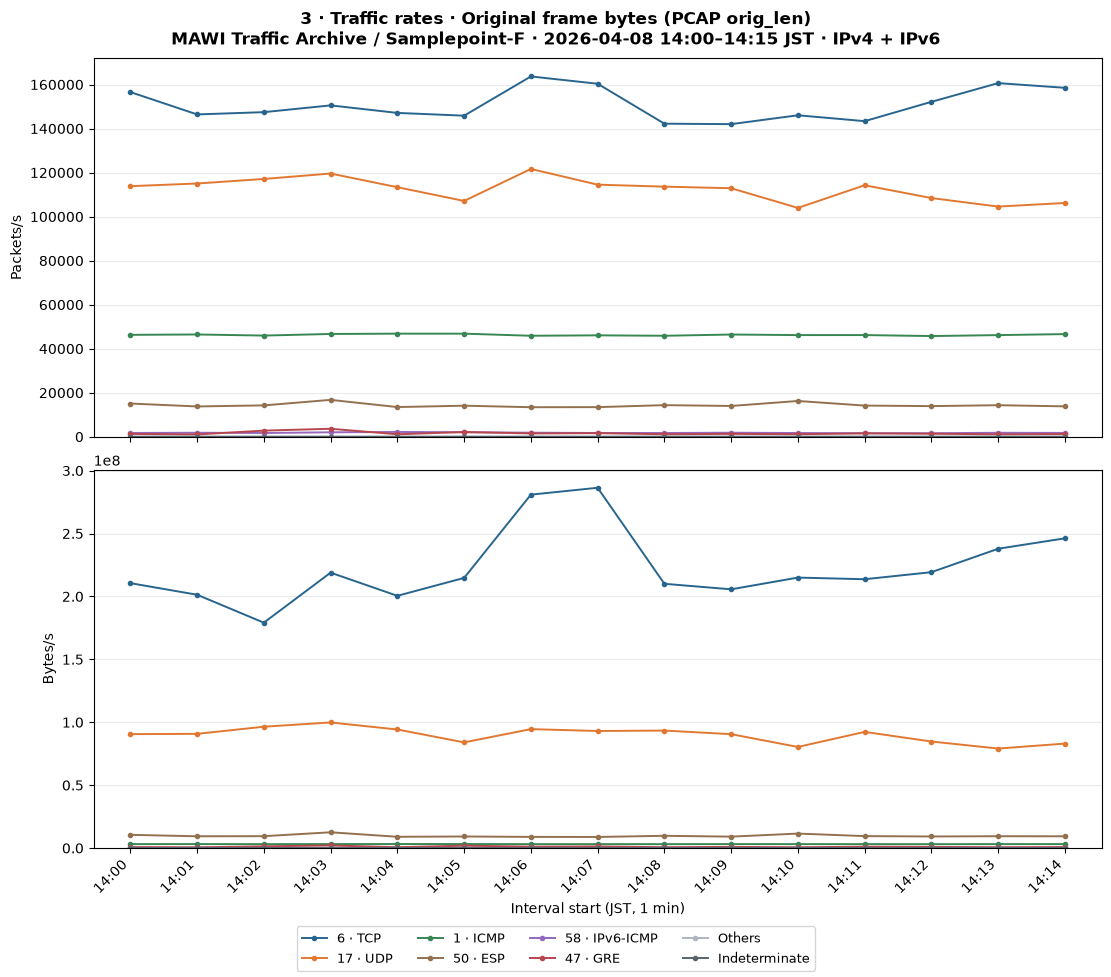

In [5]:
packet_rates = time_values("packet_count").div(interval_seconds, axis=0)
byte_rates = time_values(BYTE_METRIC).div(interval_seconds, axis=0)

fig, axes = time_figure(2, len(plot_order))
fig.suptitle(f"3 · Traffic rates · {byte_label}\n{scope_caption}", fontweight="bold")
for ax, values, unit in zip(axes, (packet_rates, byte_rates), ("Packets/s", "Bytes/s")):
    for key, flow in values.items():
        ax.plot(x, flow, marker="o", markersize=3, linewidth=1.4, color=colors[key], label=labels[key])
    ax.set(ylabel=unit, ylim=(0, None))
    ax.grid(axis="y", alpha=0.25)
    if values.empty:
        ax.text(0.5, 0.5, "No packets in this population", ha="center", transform=ax.transAxes)
time_axis(axes[-1])
handles, legend_labels = axes[-1].get_legend_handles_labels()
if handles:
    fig.legend(handles, legend_labels, loc="outside lower center", ncols=min(4, len(handles)), fontsize=9)
finish(fig, "03_traffic_rates")

## 図4　非TCP/UDPプロトコルの内訳

選択した IPv4・IPv6 のうち、IPプロトコル番号が分かり、6（TCP）・17（UDP）以外のパケットを対象とします。分母はこの部分集合のパケット数または対応するバイト数です。図4と表では Others への集約なしで番号・名称ごとの内訳を表示します。

,protocol_number,protocol,packet_count,original_frame_bytes,ip_packet_bytes,packet_pct,original_frame_bytes_pct
0,1,1 · ICMP,41653936,2831078288,1793120586,72.300015,22.360085
1,50,50 · ESP,12904414,8737145176,8556462340,22.398588,69.006679
2,58,58 · IPv6-ICMP,1618294,157060814,134404514,2.808923,1.240479
3,47,47 · GRE,1434267,935823833,915744095,2.489501,7.391212
4,97,97 · ETHERIP,1294,157868,139752,0.002246,0.001247
5,41,41 · IPv6-in-IPv4,382,35172,29824,0.000663,0.000278
6,103,103 · PIM,30,2160,1740,0.000052,0.000017
7,9,9 · IGP,7,420,280,0.000012,0.000003


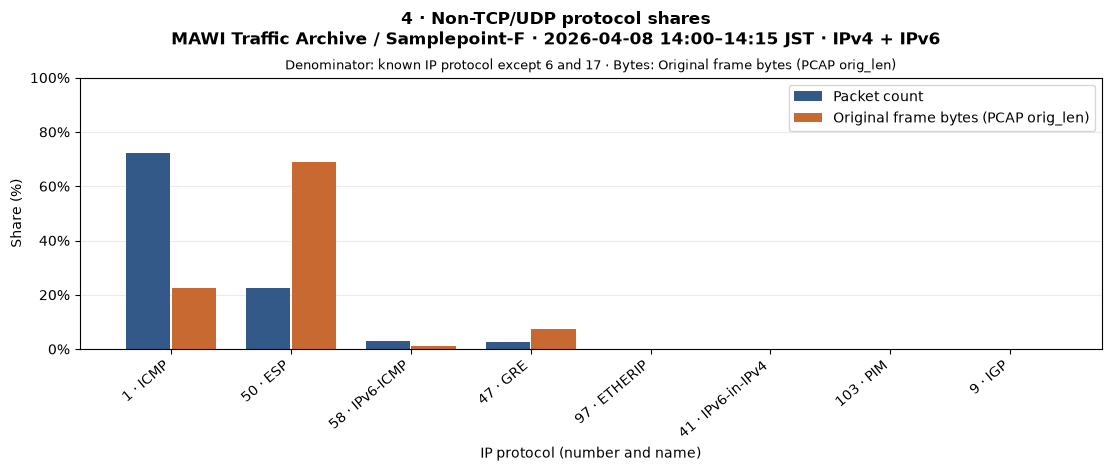

In [6]:
known_protocol = selected_counts["protocol_number"].notna()
not_tcp_udp = ~selected_counts["protocol_number"].isin([6, 17])
non_tcp_udp = selected_counts.loc[known_protocol & not_tcp_udp]
non_tcp_udp_totals = non_tcp_udp.groupby("protocol", sort=False)[MEASURES].sum()
non_tcp_udp_totals = non_tcp_udp_totals.sort_values(SORT_FIELD, ascending=False, kind="stable")
non_tcp_udp_ratios = percentages(non_tcp_udp_totals, axis=0)
non_tcp_udp_table = non_tcp_udp_totals.assign(
    protocol_number=non_tcp_udp_totals.index.astype(int),
    protocol=non_tcp_udp_totals.index.map(labels),
    packet_pct=non_tcp_udp_ratios["packet_count"],
    byte_pct=non_tcp_udp_ratios[BYTE_METRIC],
)[["protocol_number", "protocol", *MEASURES, "packet_pct", "byte_pct"]].reset_index(drop=True)
display(non_tcp_udp_table.rename(columns={"byte_pct": f"{BYTE_METRIC}_pct"}))
plot_comparison(non_tcp_udp_ratios, "4 · Non-TCP/UDP protocol shares",
                f"Denominator: known IP protocol except 6 and 17 · Bytes: {byte_label}",
                "04_non_tcp_udp_shares")